# Exploring a Delzant polygon

Workflow: put in the vertices, then ask the `Polygon` for whatever you want. Each quantity is computed the first time you ask for it and cached; `P.computed()` shows what has been filled in so far.

Conventions (normalizations of S, dσ, A_ext, …) are in `CONVENTIONS.md`. In short: u = ½ Σ ℓᵢ log ℓᵢ + h, S = −½ Σ ∂ᵢ∂ⱼ uⁱʲ, L_A(f) = ∫_∂P f dσ − ∫_P A f dμ.

In [1]:
%matplotlib inline
from fractions import Fraction
import numpy as np
from IPython.display import Markdown, display

from extremal import *            # Polygon, ToricMetric, x, y, projective_plane, hirzebruch, ...
from extremal import viz
from extremal.models import wang_zhou_nonagon
from extremal.stability import CreaseProfile, crease_search

## 1. The polygon

Vertices must be exact: ints, `Fraction`s, or strings like `'1/2'`. Either orientation is fine. This one is CP² blown up at one point (equivalently the Hirzebruch surface F₁).

In [2]:
P = Polygon([(1, 0), (3, 0), (0, 3), (0, 1)], name="CP² blown up at a point")
P.computed()   # nothing computed yet

[]

In [3]:
display(Markdown(P.report()))
P.computed()

### CP² blown up at a point

- vertices: (1, 0), (3, 0), (0, 3), (0, 1)
- Delzant: yes
- area μ(P) = 4,  boundary σ(∂P) = 8
- average scalar curvature Ŝ = 2
- A_ext = 6*x/11 + 6*y/11 + 9/11
- Futaki (F(x), F(y)) = (1/3, 1/3)

| edge | normal u | λ | lattice length |
|---|---|---|---|
| 0 | (0, 1) | 0 | 2 |
| 1 | (-1, -1) | -3 | 3 |
| 2 | (1, 0) | 0 | 2 |
| 3 | (1, 1) | 1 | 1 |

['A_ext',
 'S_hat',
 'area',
 'boundary_measure',
 'edges',
 'futaki',
 'futaki_vanishes',
 'is_delzant',
 'vertex_determinants']

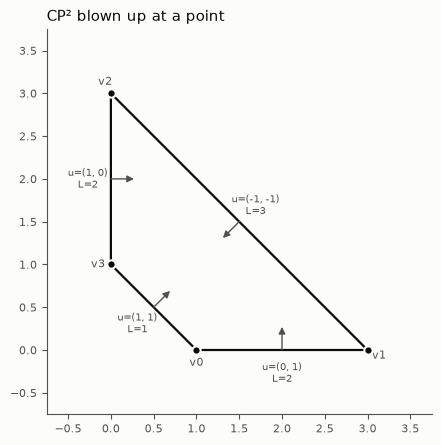

In [4]:
viz.plot_polygon(P);

## 2. Exact invariants

A_ext is the affine function with L_{A_ext}(f) = 0 for every affine f; the Futaki invariant is F(f) = L_Ŝ(f). Both are exact rationals. The dashed lines are level sets of A_ext.

S_hat  = 2
A_ext  = 6*x/11 + 6*y/11 + 9/11
Futaki = (Fraction(1, 3), Fraction(1, 3))
check: L(1), L(x), L(y) = 0 0 0


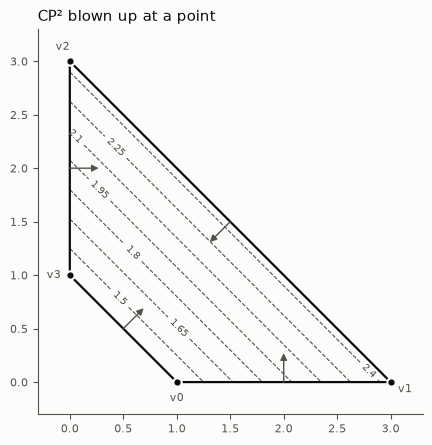

In [5]:
print("S_hat  =", P.S_hat)
print("A_ext  =", P.A_ext)
print("Futaki =", P.futaki)
print("check: L(1), L(x), L(y) =", P.L(1), P.L(x), P.L(y))

ax = viz.plot_polygon(P, labels=False)
viz.plot_A_ext(P, ax=ax);

`L` accepts any polynomial in `x, y` (exact), with weight `A` defaulting to A_ext. For example L_{A_ext}(x² + y²) is positive, as it must be for a strictly convex f if P is to be stable:

In [6]:
P.L(x**2 + y**2), P.L(x**2 + y**2, A=P.S_hat)

(Fraction(412, 55), Fraction(28, 3))

## 3. A metric and its curvature

`ToricMetric(P, h)` is the metric with symplectic potential u = u_G + h (h = 0 is Guillemin's metric). Curvature fields are vectorized functions of the momentum coordinates (x, y).

In [7]:
g = ToricMetric(P)
pts = np.array([[1.0, 1.0], [2.0, 0.5], [0.5, 2.0], [0.5, 0.5]])   # the last point is on ∂P -> nan
print("S at points:     ", g.scalar_curvature(pts[:, 0], pts[:, 1]))
print("|Ric|^2 at points:", g.ricci_norm_sq(pts[:, 0], pts[:, 1]))
print("available fields:", list(g.FIELDS))

S at points:      [1.632      2.06723103 2.06723103        nan]
|Ric|^2 at points: [2.679808   4.35338152 4.35338152        nan]
available fields: ['S', 'S - S_hat', 'S - A_ext', '|Ric|^2', '|Ric_0|^2', 'det Hess u']


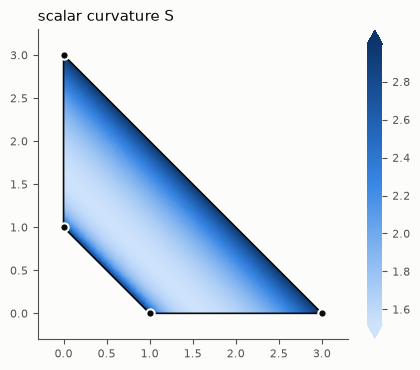

In [8]:
viz.plot_field(g, "S");

Several fields side by side. Signed quantities (S − Ŝ, S − A_ext) use a diverging scale centred at 0; each panel has its own colour scale.

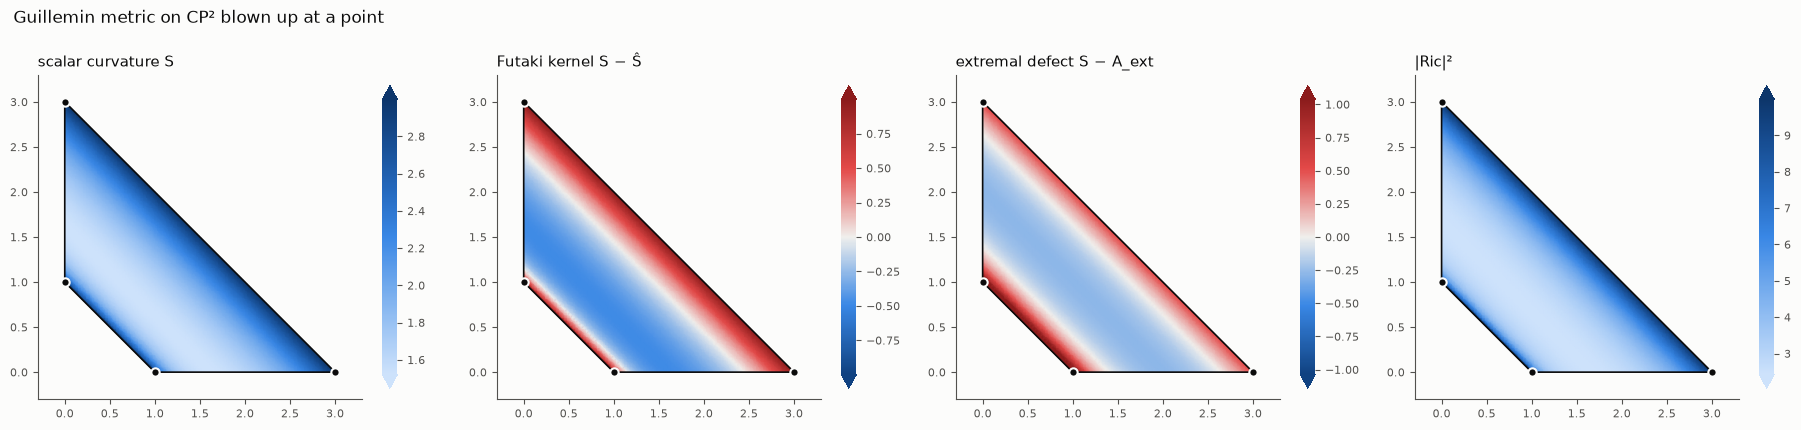

In [9]:
viz.plot_fields(g);

### The Futaki kernel

For *any* metric, F(f) = ∫_P (S − Ŝ) f dμ. Check it numerically against the exact Futaki vector:

In [10]:
Fx = integrate_numeric(P, lambda a, b: g.futaki_kernel(a, b) * a, order=40)
Fy = integrate_numeric(P, lambda a, b: g.futaki_kernel(a, b) * b, order=40)
print("numeric:", Fx, Fy)
print("exact:  ", float(P.futaki[0]), float(P.futaki[1]))

numeric: 0.33333333353437605 0.3333333333351516
exact:   0.3333333333333333 0.3333333333333333


### Changing the potential

Add a smooth `h`. u must stay convex: check the smallest eigenvalue of Hess u over the polygon first.

min eigenvalue of Hess u: 0.56726253237008


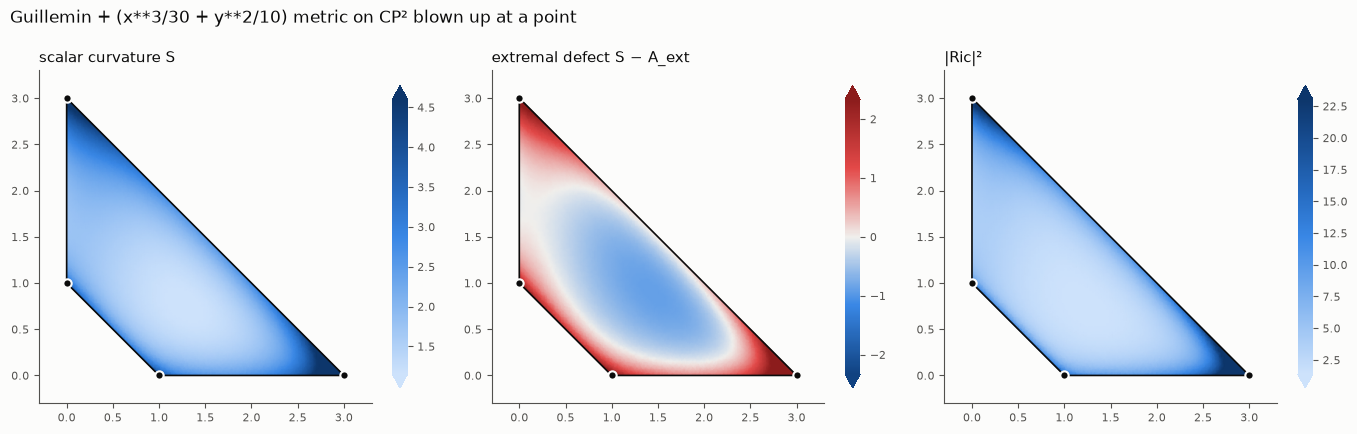

In [11]:
g2 = ToricMetric(P, h=x**3 / 30 + y**2 / 10)
mesh = viz.sample_mesh(P)
print("min eigenvalue of Hess u:", g2.min_hessian_eigenvalue(mesh.x, mesh.y).min())
viz.plot_fields(g2, names=("S", "S - A_ext", "|Ric|^2"));

## 4. Sanity check: Fubini–Study

On the standard simplex, Guillemin's metric is Fubini–Study: S ≡ 6 and |Ric|² ≡ 36 (Ric = 3g).

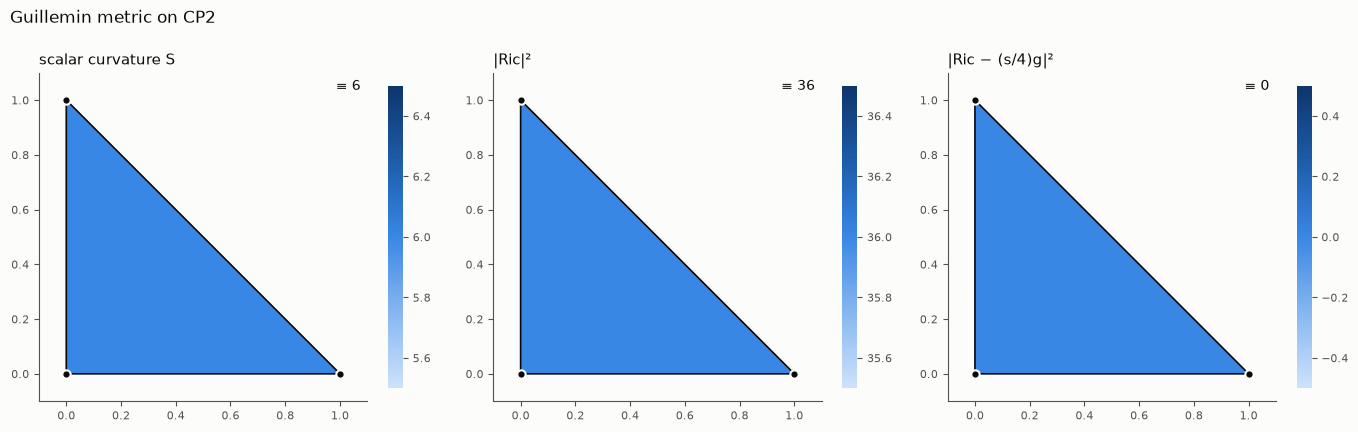

In [12]:
fs = ToricMetric(projective_plane(1))
viz.plot_fields(fs, names=("S", "|Ric|^2", "|Ric_0|^2"));

## 5. Stability: crease functions

A **simple crease** is f = max(0, n·x − s): convex, piecewise linear. If L_{A_ext}(f) < 0 then P is relatively K-unstable and has no extremal metric.

**Why creases are enough (dimension 2).** Wang–Zhou (Adv. Math. 2011; Cor. 3.5 / Thm 3.4 in B. Zhou's thesis): if L_A(u) < 0 for *some* convex u, then L_A(f) < 0 for some simple crease f, with **no sign condition on A** (Donaldson 2002, Prop. 5.3.1, had the borderline case for A > 0). Donaldson (2002, Prop. 6.1): the crease can be taken rational. So checking rational creases decides whether L_{A_ext} ≥ 0 on all convex functions.

**Exact one-variable reduction.** For a fixed direction n, L(s) = ∫_s^{t_max} (t − s) dρ(t), where ρ has density (boundary crossings) Σ Lᵢ/|Δtᵢ| minus (A_ext integrated along the chord {n·x = t})/|n|. ρ is quadratic between vertex values, so L is piecewise quartic in s and is minimized exactly. `CreaseProfile` builds this; it is exact for rational n and s.

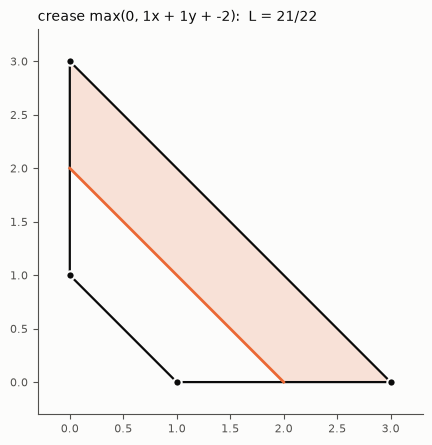

In [13]:
viz.plot_crease(P, 1, 1, -2);

L at s = 2 (exact): 21/22   direct: 21/22


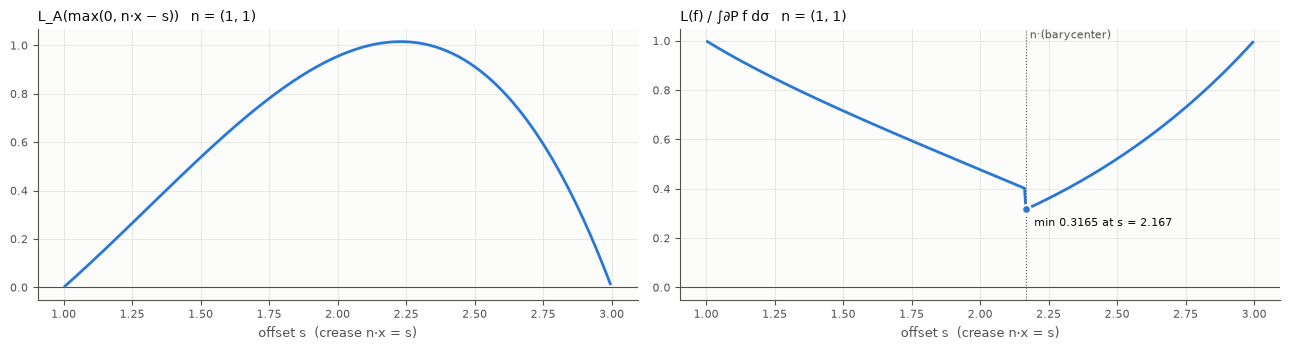

In [14]:
import matplotlib.pyplot as plt

prof = CreaseProfile(P, (1, 1))
print("L at s = 2 (exact):", prof.L(2), "  direct:", P.L_crease(1, 1, -2))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
viz.plot_crease_profile(prof, ax=axes[0])
viz.plot_crease_profile(prof, ax=axes[1], normalized=True)
fig.tight_layout()

### Searching all directions

L is homogeneous in (n, s) and n, −n give the same values, so the creases form a half-circle of directions θ times one offset. For each θ, `crease_search` takes the scale-invariant **margin** min_s L(f) / ∫_∂P f dσ (f normalized to vanish at the barycenter, as in Donaldson's uniform stability). If the margin goes negative, it finds a nearby *rational* crease and checks L < 0 exactly. Floats only locate candidates; a positive result is evidence, not proof.

Calabi constructed an extremal metric on this P, so the margin should be positive everywhere.

crease stability margin min L(f)/∫_∂P f dσ = 0.299379 at θ = 1.622°, s = 1.11355
no destabilizing crease found (sampled search, not a proof)


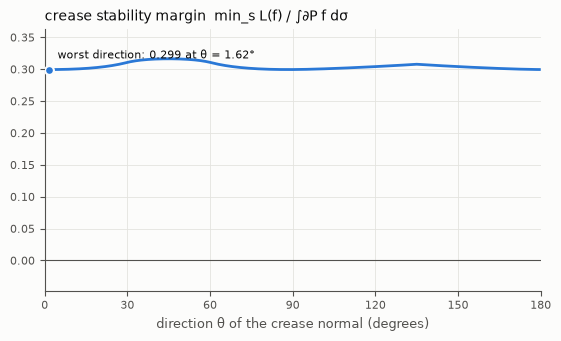

In [15]:
result = crease_search(P)
print(result)
viz.plot_crease_margin(result);

### An unstable example: the Wang–Zhou nonagon

B. Zhou's thesis (§3.2.2) gives a 9-vertex Delzant polygon P* depending on a parameter α, relatively K-unstable for α large. The search finds an exact rational destabilizing crease:

crease stability margin min L(f)/∫_∂P f dσ = -0.000160798 at θ = 19.700°, s = 3329.66
UNSTABLE: exact certificate f = max(0, 53x + 19y + -1097511911/5880), L = -84.3486 (exact rational: -71579749623097533650280858767758463135659/848618549536341953812177411590660768000)


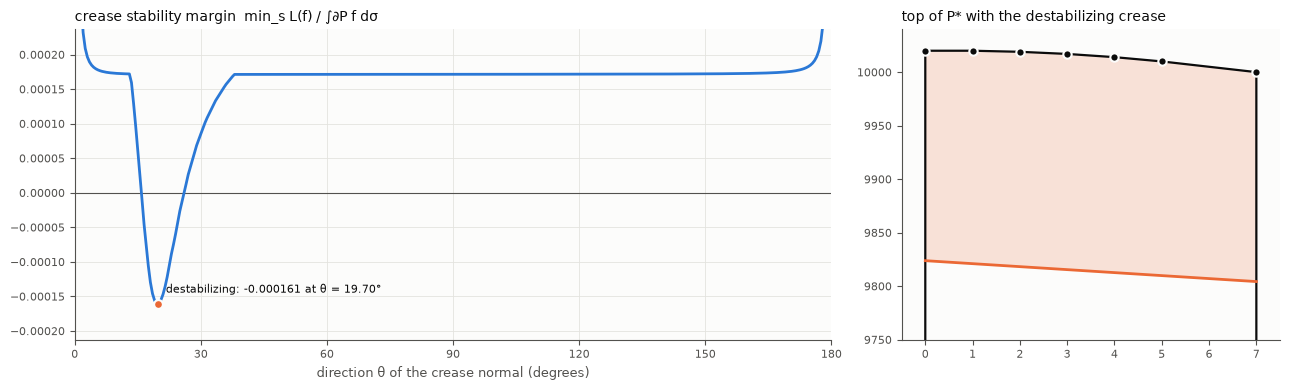

In [16]:
Q = wang_zhou_nonagon(10_000)
rq = crease_search(Q)
print(rq)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={'width_ratios': [2, 1]})
viz.plot_crease_margin(rq, ax=axes[0])
viz.plot_crease(Q, *rq.certificate, ax=axes[1])
axes[1].set_aspect('auto')   # the polygon is 7 wide and ~20000 tall: zoom on the top
axes[1].set_xlim(-0.5, 7.5); axes[1].set_ylim(9750, 10040)
axes[1].set_title('top of P* with the destabilizing crease', fontsize=10, loc='left')
fig.tight_layout()

Where does instability set in? (Bisection gives a threshold between α ≈ 6854 and 6882.)

In [17]:
for alpha in [100, 1000, 3000, 6000, 6800, 6900, 8000, 10_000]:
    r = crease_search(wang_zhou_nonagon(alpha), n_angles=180)
    print(f"α = {alpha:>6}:  margin = {r.best_margin:+.3e}   {'UNSTABLE (exact)' if r.unstable else ''}")

α =    100:  margin = +1.539e-02   
α =   1000:  margin = +1.695e-03   


α =   3000:  margin = +5.693e-04   
α =   6000:  margin = +7.445e-05   


α =   6800:  margin = +4.696e-06   
α =   6900:  margin = -2.637e-06   UNSTABLE (exact)


α =   8000:  margin = -7.355e-05   UNSTABLE (exact)
α =  10000:  margin = -1.608e-04   UNSTABLE (exact)


### Horizontal versus tilted creases

Zhou's argument uses horizontal creases max(0, y − α + k) with α ≫ k ≫ 1: their value tends to C − k/7 as α → ∞ (slope −1/7 = 27 − 27⅐ from the thesis; numerically C ≈ 72.48, matching 1522/21). So k must exceed about 500 before they destabilize, and α must be much larger than k. Tilted creases destabilize far earlier.

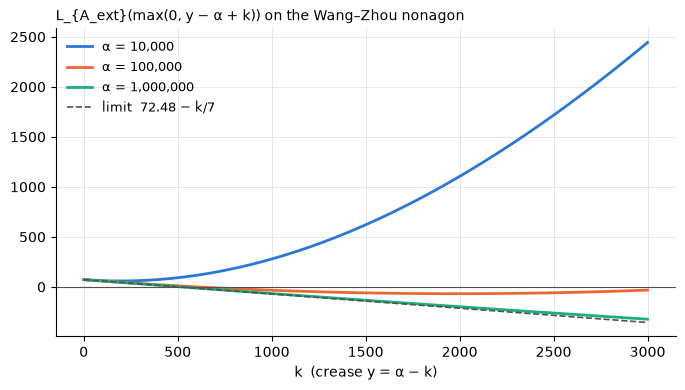

In [18]:
from fractions import Fraction

ks = np.linspace(1, 3000, 240)
far = CreaseProfile(wang_zhou_nonagon(10**10), (0, 1))   # effectively the α → ∞ limit
C = float(far.L(Fraction(10**10 - 10)) + Fraction(10, 7))

fig, ax = plt.subplots(figsize=(8, 4))
for alpha, color in zip([10_000, 100_000, 1_000_000], ['#2a78d6', '#eb6834', '#1baf7a']):
    prof = CreaseProfile(wang_zhou_nonagon(alpha), (0, 1))
    ax.plot(ks, prof.L_values(alpha - ks), color=color, lw=2, label=f'α = {alpha:,}')
ax.plot(ks, C - ks / 7, color='#52514e', lw=1.2, ls='--', label=f'limit  {C:.2f} − k/7')
ax.axhline(0, color='#52514e', lw=0.8)
ax.set_xlabel('k  (crease y = α − k)')
ax.set_title('L_{A_ext}(max(0, y − α + k)) on the Wang–Zhou nonagon', loc='left', fontsize=10)
ax.legend(frameon=False, fontsize=9)
ax.grid(True, color='#e4e3df', lw=0.6)
for side in ('top', 'right'): ax.spines[side].set_visible(False)

Same comparison through the normalized margin: θ = 90° is the horizontal direction, against the worst direction overall. Thresholds by bisection: tilted creases destabilize from α ≈ 6870, horizontal ones only from α ≈ 51600.

In [19]:
print(f"{'α':>8} | {'horizontal margin':>18} | {'best margin':>12} | {'best θ':>7} | exact certificate")
for alpha in [6_000, 7_000, 10_000, 50_000, 53_000, 100_000]:
    r = crease_search(wang_zhou_nonagon(alpha), n_angles=180)
    horizontal = r.margin[90]          # theta[90] = 90°, normal (0, 1)
    print(f"{alpha:>8} | {horizontal:>+18.3e} | {r.best_margin:>+12.3e} | {np.degrees(r.best_theta):>6.1f}° | "
          f"{'yes' if r.unstable else 'no'}")

       α |  horizontal margin |  best margin |  best θ | exact certificate
    6000 |         +2.856e-04 |   +7.445e-05 |   19.8° | no


    7000 |         +2.448e-04 |   -9.551e-06 |   19.8° | yes
   10000 |         +1.714e-04 |   -1.608e-04 |   19.7° | yes


   50000 |         +2.266e-06 |   -4.455e-04 |   19.6° | yes
   53000 |         -1.592e-06 |   -4.432e-04 |   19.6° | yes


  100000 |         -3.274e-05 |   -4.485e-04 |   19.6° | yes


## 6. Random Delzant polygons

Built from CP² or F_n by corner cuts (toric blow-ups); the history records how. Change the seeds to explore.

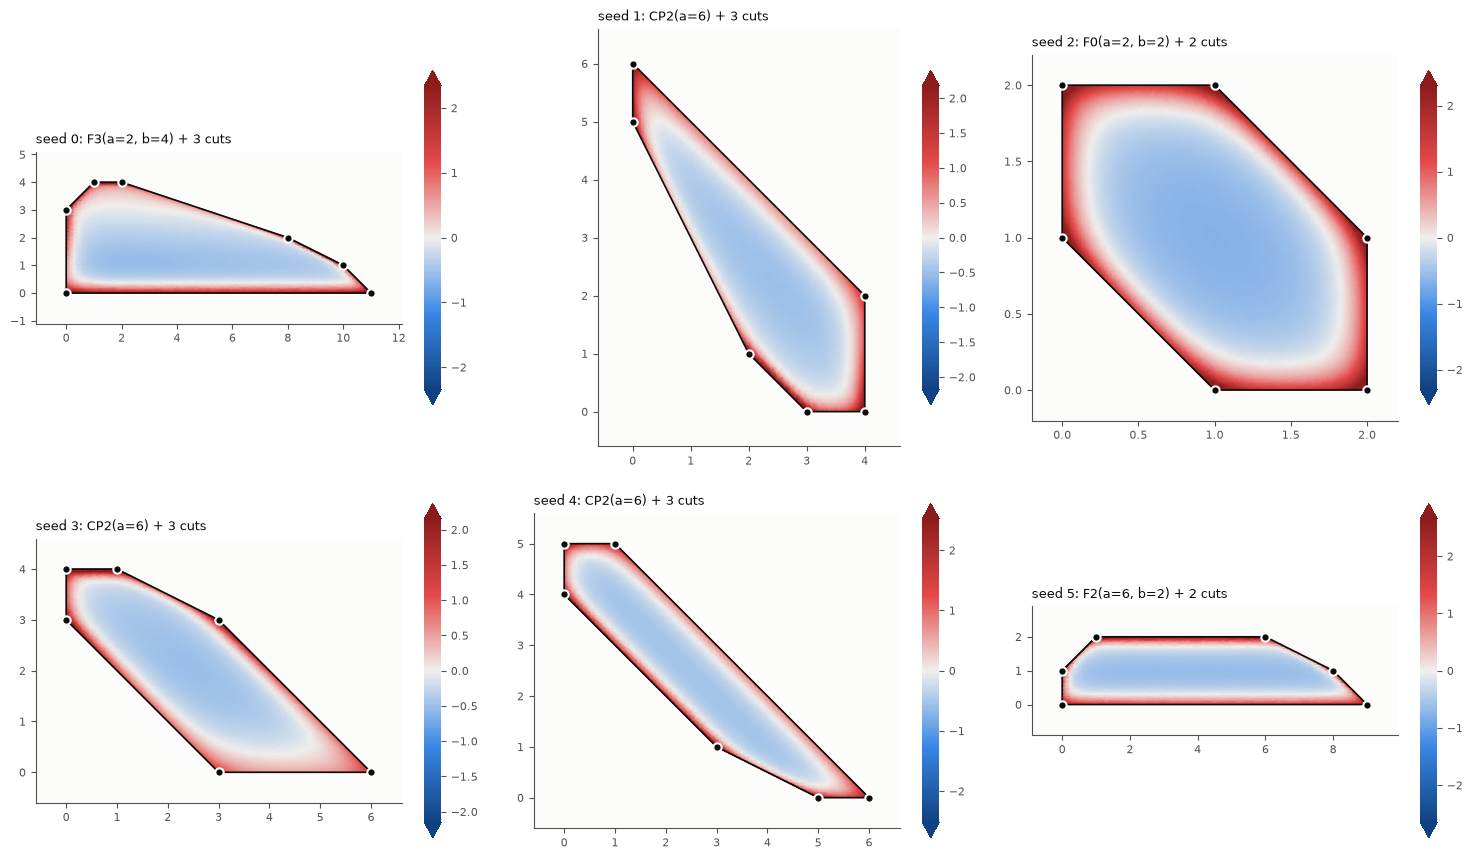

In [20]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, seed in zip(axes.ravel(), range(6)):
    Q, history = random_delzant(n_blowups=3, seed=seed)
    viz.plot_field(ToricMetric(Q), "S - A_ext", ax=ax, resolution=80)
    ax.set_title(f"seed {seed}: " + ", ".join(history[:1]) + f" + {len(history) - 1} cuts", fontsize=9, loc="left")
fig.tight_layout()

In [21]:
Q, history = random_delzant(n_blowups=3, seed=4)
print("\n".join(history))
display(Markdown(Q.report()))
print(crease_search(Q))

CP2(a=6)
blow up vertex 0 by 4
blow up vertex 3 by 1
blow up vertex 1 by 1


### random

- vertices: (0, 4), (3, 1), (5, 0), (6, 0), (1, 5), (0, 5)
- Delzant: yes
- area μ(P) = 9,  boundary σ(∂P) = 12
- average scalar curvature Ŝ = 4/3
- A_ext = 180*x/451 + 180*y/451 - 312/451
- Futaki (F(x), F(y)) = (10/9, 0)

| edge | normal u | λ | lattice length |
|---|---|---|---|
| 0 | (1, 1) | 4 | 3 |
| 1 | (1, 2) | 5 | 1 |
| 2 | (0, 1) | 0 | 1 |
| 3 | (-1, -1) | -6 | 5 |
| 4 | (0, -1) | -5 | 1 |
| 5 | (1, 0) | 0 | 1 |

crease stability margin min L(f)/∫_∂P f dσ = 0.196958 at θ = 99.394°, s = 2.04633
no destabilizing crease found (sampled search, not a proof)


## 7. A family: the symmetric pentagon

`ParametricPolygon` fixes the normals and makes the support constants symbolic, so invariants come out as exact rational functions of the Kähler class. Here: the unit square cut by x + y ≥ e, i.e. CP¹×CP¹ blown up at a fixed point (≅ CP² blown up at two points), with both CP¹ factors the same size. Up to scale the symmetric classes form this one-parameter family, 0 < e < 1. This is the surface of Chen–LeBrun–Weber.

In [22]:
import sympy as sp
from fractions import Fraction
from extremal import ParametricPolygon

e = sp.Symbol('e', positive=True)
square = Polygon([(1, 0), (2, 0), (2, 2), (0, 2), (0, 1)])   # edges: bottom, right, top, left, cut
Pe = ParametricPolygon.from_polygon(square, {1: -1, 2: -1, 4: e}, params=(e,), name='symmetric pentagon')
print('Delzant:', Pe.is_delzant, '   valid iff all > 0:', Pe.constraints())
c0, c1, c2 = Pe.A_ext_coefficients   # c1 = c2 by the x <-> y symmetry
display(Markdown(
    f'- μ(P) = ${sp.latex(Pe.area)}$\n'
    f'- Ŝ = ${sp.latex(Pe.S_hat)}$\n'
    f'- A_ext = c₀ + c₁ (x + y), with c₀ = ${sp.latex(c0)}$ and c₁ = ${sp.latex(c1)}$\n'
    f'- Futaki F(x) = F(y) = ${sp.latex(Pe.futaki[0])}$\n'
    f'- ∫ A_ext² dμ = ${sp.latex(Pe.calabi_energy)}$'
))

Delzant: True    valid iff all > 0: (1 - e, 1, 1, 1 - e, e)


- μ(P) = $- \frac{e^{2} - 2}{2}$
- Ŝ = $\frac{2 \left(e - 4\right)}{e^{2} - 2}$
- A_ext = c₀ + c₁ (x + y), with c₀ = $\frac{6 \left(3 e^{5} - 12 e^{4} + 16 e^{3} - 14 e + 8\right)}{e^{6} - 18 e^{4} + 48 e^{3} - 42 e^{2} + 12}$ and c₁ = $- \frac{24 e \left(e - 1\right) \left(e^{2} - 3 e + 3\right)}{e^{6} - 18 e^{4} + 48 e^{3} - 42 e^{2} + 12}$
- Futaki F(x) = F(y) = $\frac{e \left(e - 1\right) \left(e^{2} - 3 e + 3\right)}{3 \left(e^{2} - 2\right)}$
- ∫ A_ext² dμ = $- \frac{6 \left(3 e^{6} - 24 e^{5} + 80 e^{4} - 128 e^{3} + 82 e^{2} + 16 e - 32\right)}{e^{6} - 18 e^{4} + 48 e^{3} - 42 e^{2} + 12}$

`at(...)` gives an ordinary `Polygon` at a rational value, so everything above applies. The Guillemin metric at e = 1/2:

### symmetric pentagon

- vertices: (1/2, 0), (1, 0), (1, 1), (0, 1), (0, 1/2)
- Delzant: yes
- area μ(P) = 7/8,  boundary σ(∂P) = 7/2
- average scalar curvature Ŝ = 4
- A_ext = 672*x/409 + 672*y/409 + 900/409
- Futaki (F(x), F(y)) = (1/12, 1/12)

| edge | normal u | λ | lattice length |
|---|---|---|---|
| 0 | (0, 1) | 0 | 1/2 |
| 1 | (-1, 0) | -1 | 1 |
| 2 | (0, -1) | -1 | 1 |
| 3 | (1, 0) | 0 | 1/2 |
| 4 | (1, 1) | 1/2 | 1/2 |

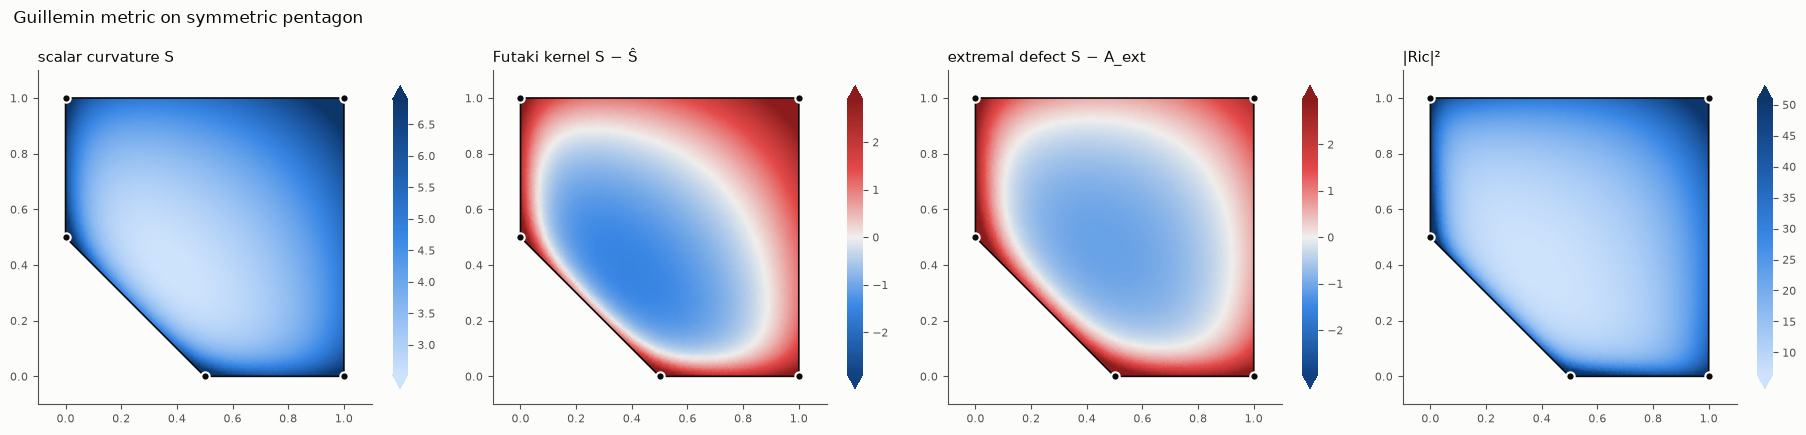

In [23]:
Q = Pe.at(e=Fraction(1, 2))
display(Markdown(Q.report()))
viz.plot_fields(ToricMetric(Q));

Scalar curvature of the Guillemin metric across the family (each panel has its own colour scale). Guillemin's metric is not extremal, so none of these is affine.

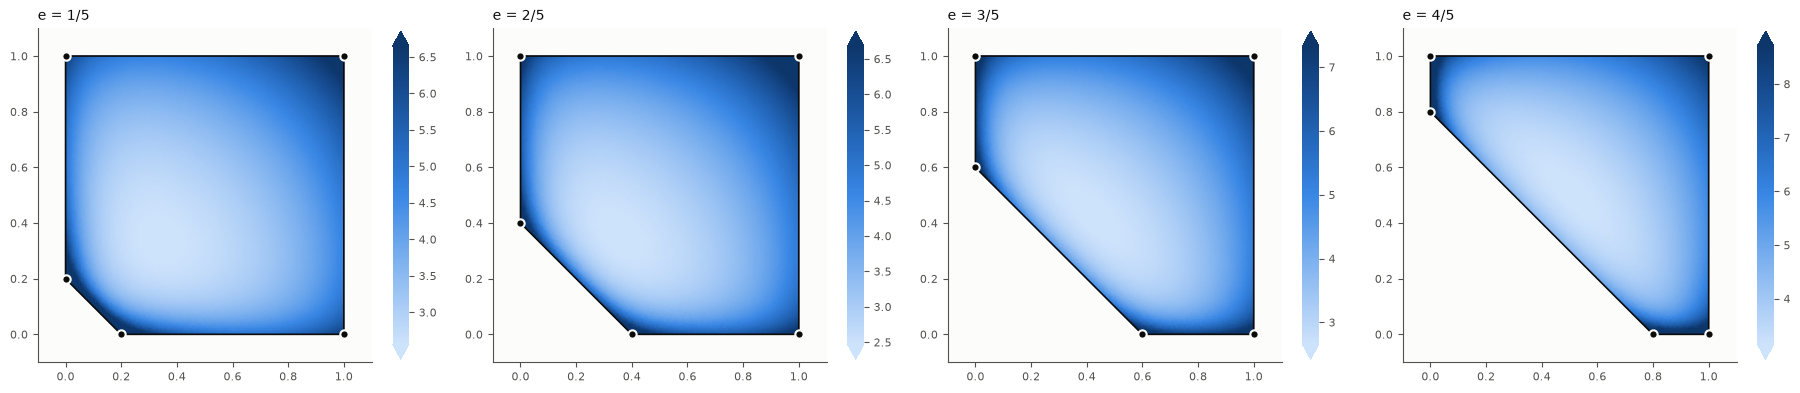

In [24]:
es = [Fraction(1, 5), Fraction(2, 5), Fraction(3, 5), Fraction(4, 5)]
fig, axes = plt.subplots(1, len(es), figsize=(4.6 * len(es), 4.4))
for ax, ev in zip(axes, es):
    viz.plot_field(ToricMetric(Pe.at(e=ev)), 'S', ax=ax, resolution=90)
    ax.set_title(f'e = {ev}', loc='left', fontsize=10)
fig.tight_layout()

The extremal invariants across the family, from the exact formulas: the Calabi energy ∫ A_ext² dμ (which is what an extremal metric in the class would have as ∫ S² dμ; scale-invariant in real dimension 4) and the Futaki invariant. Both are exact rational functions of e; the curves just evaluate them.

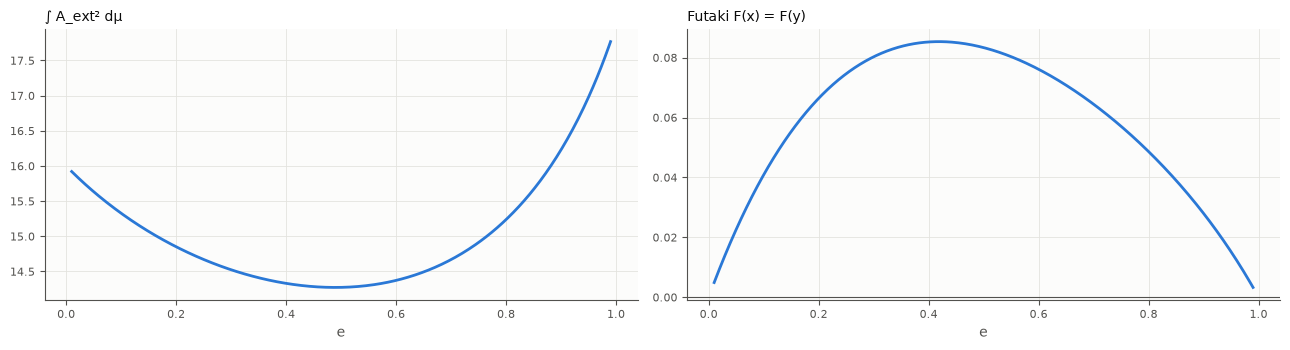

In [25]:
E = sp.lambdify(e, Pe.calabi_energy)
F = sp.lambdify(e, Pe.futaki[0])
t = np.linspace(0.01, 0.99, 400)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, fn, label in ((axes[0], E, '∫ A_ext² dμ'), (axes[1], F, 'Futaki F(x) = F(y)')):
    viz._line_axes(ax)
    ax.plot(t, fn(t), color='#2a78d6', lw=2)
    ax.set_xlabel('e', color=viz.INK_2)
    ax.set_title(label, loc='left', fontsize=10, color=viz.INK)
axes[1].axhline(0, color=viz.INK_2, lw=0.8)
fig.tight_layout()

In [26]:
print(crease_search(Q))

crease stability margin min L(f)/∫_∂P f dσ = 0.284744 at θ = 45.000°, s = 0.77445
no destabilizing crease found (sampled search, not a proof)


## 8. Checking Chen–LeBrun–Weber

Chen–LeBrun–Weber (*On conformally Kähler, Einstein manifolds*, JAMS 2008, arXiv:0705.0710, §3) find the Einstein metric on CP² # 2 CP̄² as s⁻²g for an extremal g in the Kähler class that is critical for

  𝒜([ω]) = (c₁·[ω])²/[ω]² − 𝓕(ξ, [ω])/32π²,  which equals (1/32π²) ∫ s² dμ_g for an extremal metric.

Their formula for 𝒜 uses the LeBrun–Simanca computation of the Futaki invariant. Here it is recomputed independently from the polygon, with Donaldson's toric formulas.

| CLW | here |
|---|---|
| class (β+ε)(F₁+F₂) − εE | square of lattice side β+ε, corner cut of lattice length ε (areas = 2π × lattice lengths) |
| x = ε/β | x = e/(1 − e) on the unit square of §7; x = 1 is the anticanonical class |
| 𝒜 = (1/32π²) ∫ s² dμ_g | ½ ∫ A_ext² dμ  (s = 2S, dμ_g = (2π)² dμ) |

In [27]:
beta, eps, xx = sp.symbols('beta epsilon x', positive=True)
Pclw = ParametricPolygon.from_polygon(square, {1: -(beta + eps), 2: -(beta + eps), 4: eps},
                                      params=(beta, eps), name='CLW class')
print('lattice lengths:', Pclw.lattice_lengths, '   [ω]² =', sp.expand(2 * Pclw.area))

f_clw = 3 * (32 + 176*xx + 318*xx**2 + 280*xx**3 + 132*xx**4 + 32*xx**5 + 3*xx**6) / (
    12 + 72*xx + 138*xx**2 + 120*xx**3 + 54*xx**4 + 12*xx**5 + xx**6)
print('ours − CLW f(ε/β) =', sp.simplify(Pclw.calabi_energy / 2 - f_clw.subs(xx, eps / beta)))

# the two LeBrun–Simanca inputs, for the Hamiltonian t = x + y of the diagonal circle action
w2 = 2 * Pclw.area
t0 = Pclw.integrate(x + y) / Pclw.area
variance = Pclw.integrate(sp.expand((x + y - t0)**2))
futaki_t = Pclw.futaki[0] + Pclw.futaki[1]
clw_var = 12*beta**6 + 72*beta**5*eps + 138*beta**4*eps**2 + 120*beta**3*eps**3 + 54*beta**2*eps**4 + 12*beta*eps**5 + eps**6
clw_fut = 4*beta*eps*(eps**2/3 + beta*eps + beta**2)
print('[ω]² ∫(t − t₀)² dμ  / CLW:', sp.simplify(w2 * variance / clw_var), '  (a constant: normalization of t)')
print('[ω]² 𝓕(Ξ)          / CLW:', sp.simplify(w2 * futaki_t / clw_fut), '  (a constant: normalization of t)')

lattice lengths: (beta, beta + epsilon, beta + epsilon, beta, epsilon)    [ω]² = 2*beta**2 + 4*beta*epsilon + epsilon**2


ours − CLW f(ε/β) = 0


[ω]² ∫(t − t₀)² dμ  / CLW: 1/36   (a constant: normalization of t)
[ω]² 𝓕(Ξ)          / CLW: 1/2   (a constant: normalization of t)


Both LeBrun–Simanca inputs have exactly the right dependence on (β, ε); the constants are normalizations of t and of 2π, and they combine correctly, since 𝒜 agrees identically. The critical class:

f′(x) = 0  ⟺  $x^{10} + 15 x^{9} + 96 x^{8} + 336 x^{7} + 680 x^{6} + 720 x^{5} + 120 x^{4} - 624 x^{3} - 708 x^{2} - 300 x - 48 = 0$ (irreducible over ℚ: True)

x₀ = 0.95771280518776186069   (CLW: x ≈ 0.958)
e₀ = x₀/(1 + x₀) = 0.48919984721451969413
f(x₀) = 7.13647447062311  < 8   f′(1) = 3456/167281 = 3·1152/409²


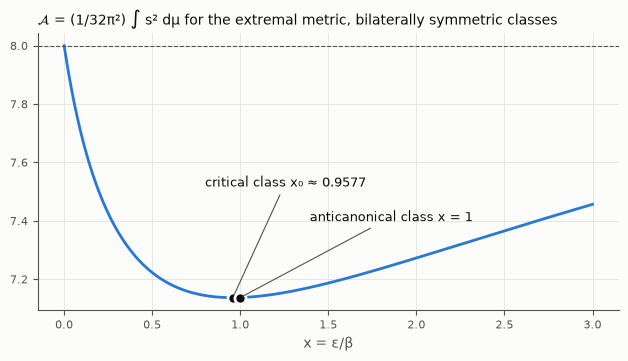

In [28]:
num = sp.Poly(sp.numer(sp.together(sp.diff(f_clw, xx))), xx).primitive()[1]   # drop the content 12
x0 = [r for r in num.real_roots() if r > 0][0]
display(Markdown(f'f′(x) = 0  ⟺  ${sp.latex(num.as_expr())} = 0$ (irreducible over ℚ: {num.is_irreducible})'))
print('x₀ =', sp.N(x0, 20), '  (CLW: x ≈ 0.958)')
print('e₀ = x₀/(1 + x₀) =', sp.N(x0 / (1 + x0), 20))
print('f(x₀) =', sp.N(f_clw.subs(xx, x0), 15), ' < 8   f′(1) =', sp.diff(f_clw, xx).subs(xx, 1), '= 3·1152/409²')

fx = sp.lambdify(xx, f_clw)
ts = np.linspace(0, 3, 400)
ax = viz._line_axes(None, figsize=(7.5, 3.6))
ax.plot(ts, fx(ts), color='#2a78d6', lw=2)
ax.axhline(8, color=viz.INK_2, lw=0.8, ls='--')
for xv, label, offset in ((float(x0), f'critical class x₀ ≈ {float(x0):.4f}', (-20, 80)),
                          (1.0, 'anticanonical class x = 1', (50, 55))):
    ax.plot([xv], [fx(xv)], 'o', ms=8, color=viz.INK, mec=viz.SURFACE, mew=2, zorder=3)
    ax.annotate(label, (xv, fx(xv)), xytext=offset, textcoords='offset points', fontsize=9, color=viz.INK,
                arrowprops=dict(arrowstyle='-', color=viz.INK_2, lw=0.8))
ax.set_xlabel('x = ε/β', color=viz.INK_2)
ax.set_title(r'$\mathcal{A}$ = (1/32π²) ∫ s² dμ for the extremal metric, bilaterally symmetric classes', loc='left', fontsize=10, color=viz.INK);

CLW's Lemma (s > 0 for every bilaterally symmetric extremal metric), exactly: the extremal s = 2 A_ext is affine and increasing in x + y, so its minimum is on the exceptional curve E (the cut edge). With β = 1:

In [29]:
Px = ParametricPolygon.from_polygon(square, {1: -(1 + xx), 2: -(1 + xx), 4: xx}, params=(xx,))
c0, c1, c2 = Px.A_ext_coefficients
vx, vy = Px.vertices[0]   # an endpoint of the cut edge E
display(Markdown(f'$s_{{\\min}} = {sp.latex(sp.factor(2 * (c0 + c1 * vx + c2 * vy)))}$ (lattice units, β = 1)'))

$s_{\min} = \frac{12 \left(x^{5} + 8 x^{4} + 24 x^{3} + 36 x^{2} + 26 x + 8\right)}{x^{6} + 12 x^{5} + 54 x^{4} + 120 x^{3} + 138 x^{2} + 72 x + 12}$ (lattice units, β = 1)